
⏱ Training Time: 0.24 seconds

Train Scores Scores:
  MAE:  0.04031
  RMSE: 0.05295
  R²:   0.97659

Test Scores Scores:
  MAE:  0.06291
  RMSE: 0.07969
  R²:   0.95660

📉 5-Fold Cross-Validation R² Scores:
  Fold 1: R² = 0.90934
  Fold 2: R² = 0.90635
  Fold 3: R² = 0.93695
  Fold 4: R² = 0.86110
  Fold 5: R² = 0.94174

Mean R²: 0.91110
Std Dev: 0.02875


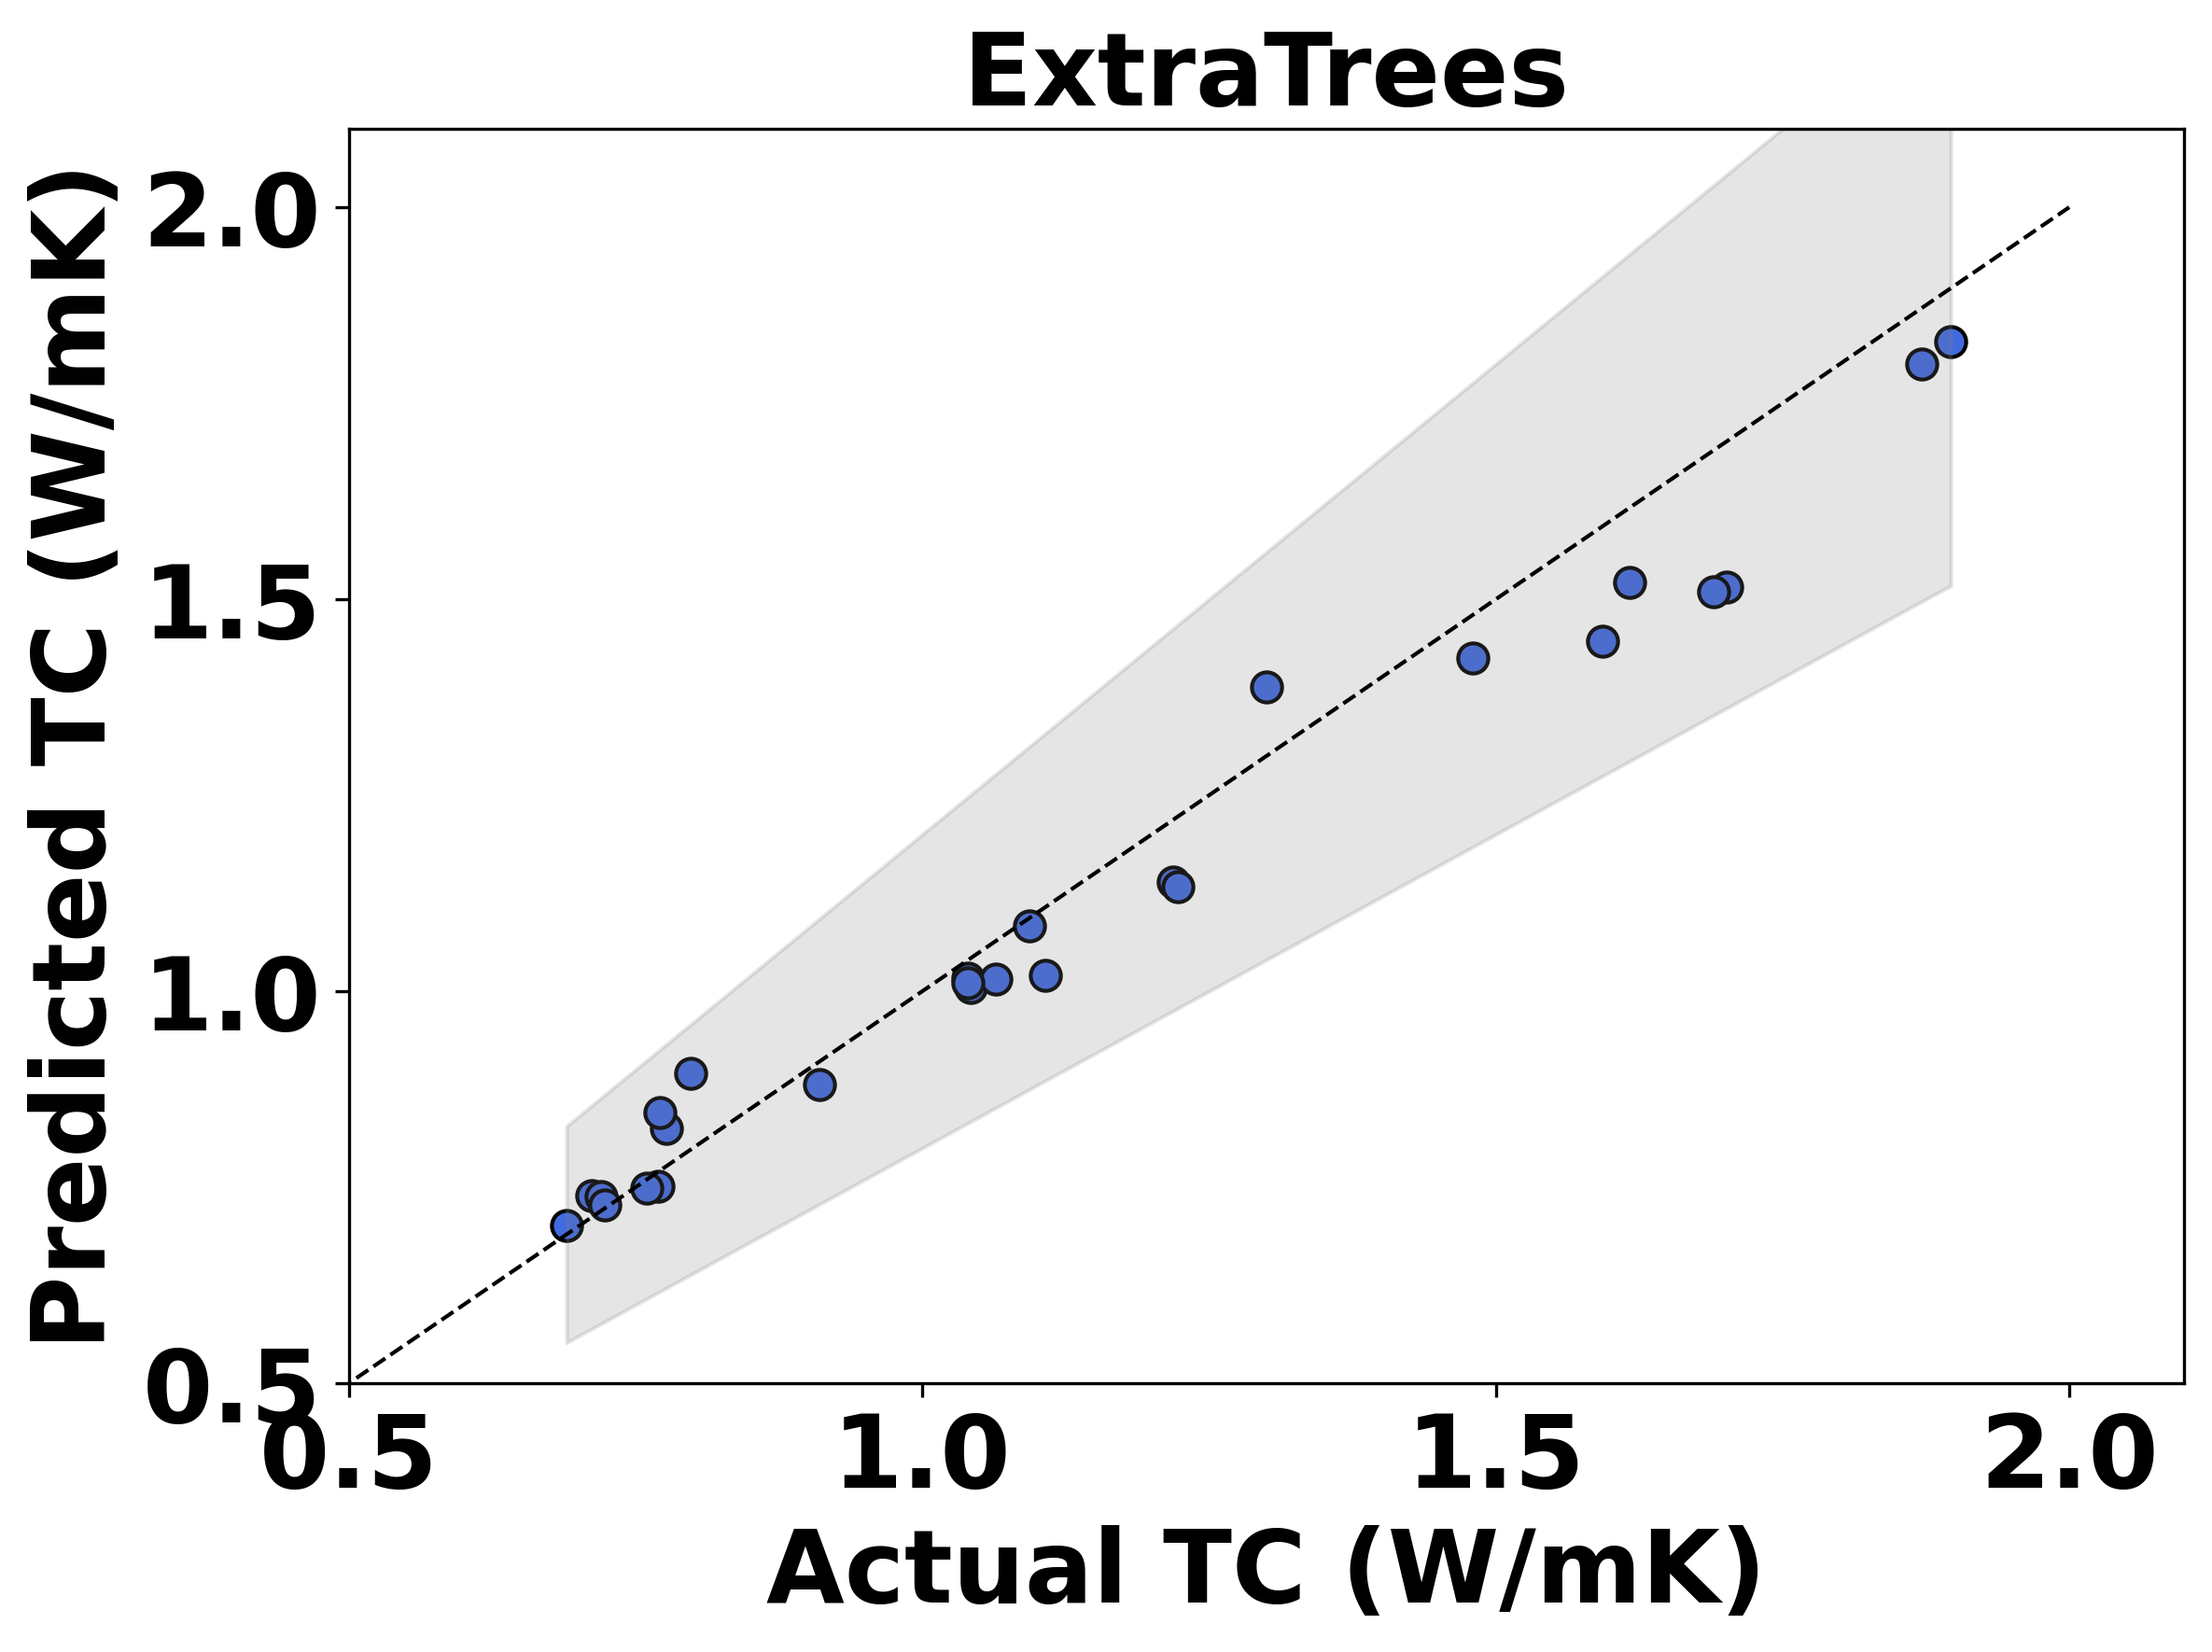

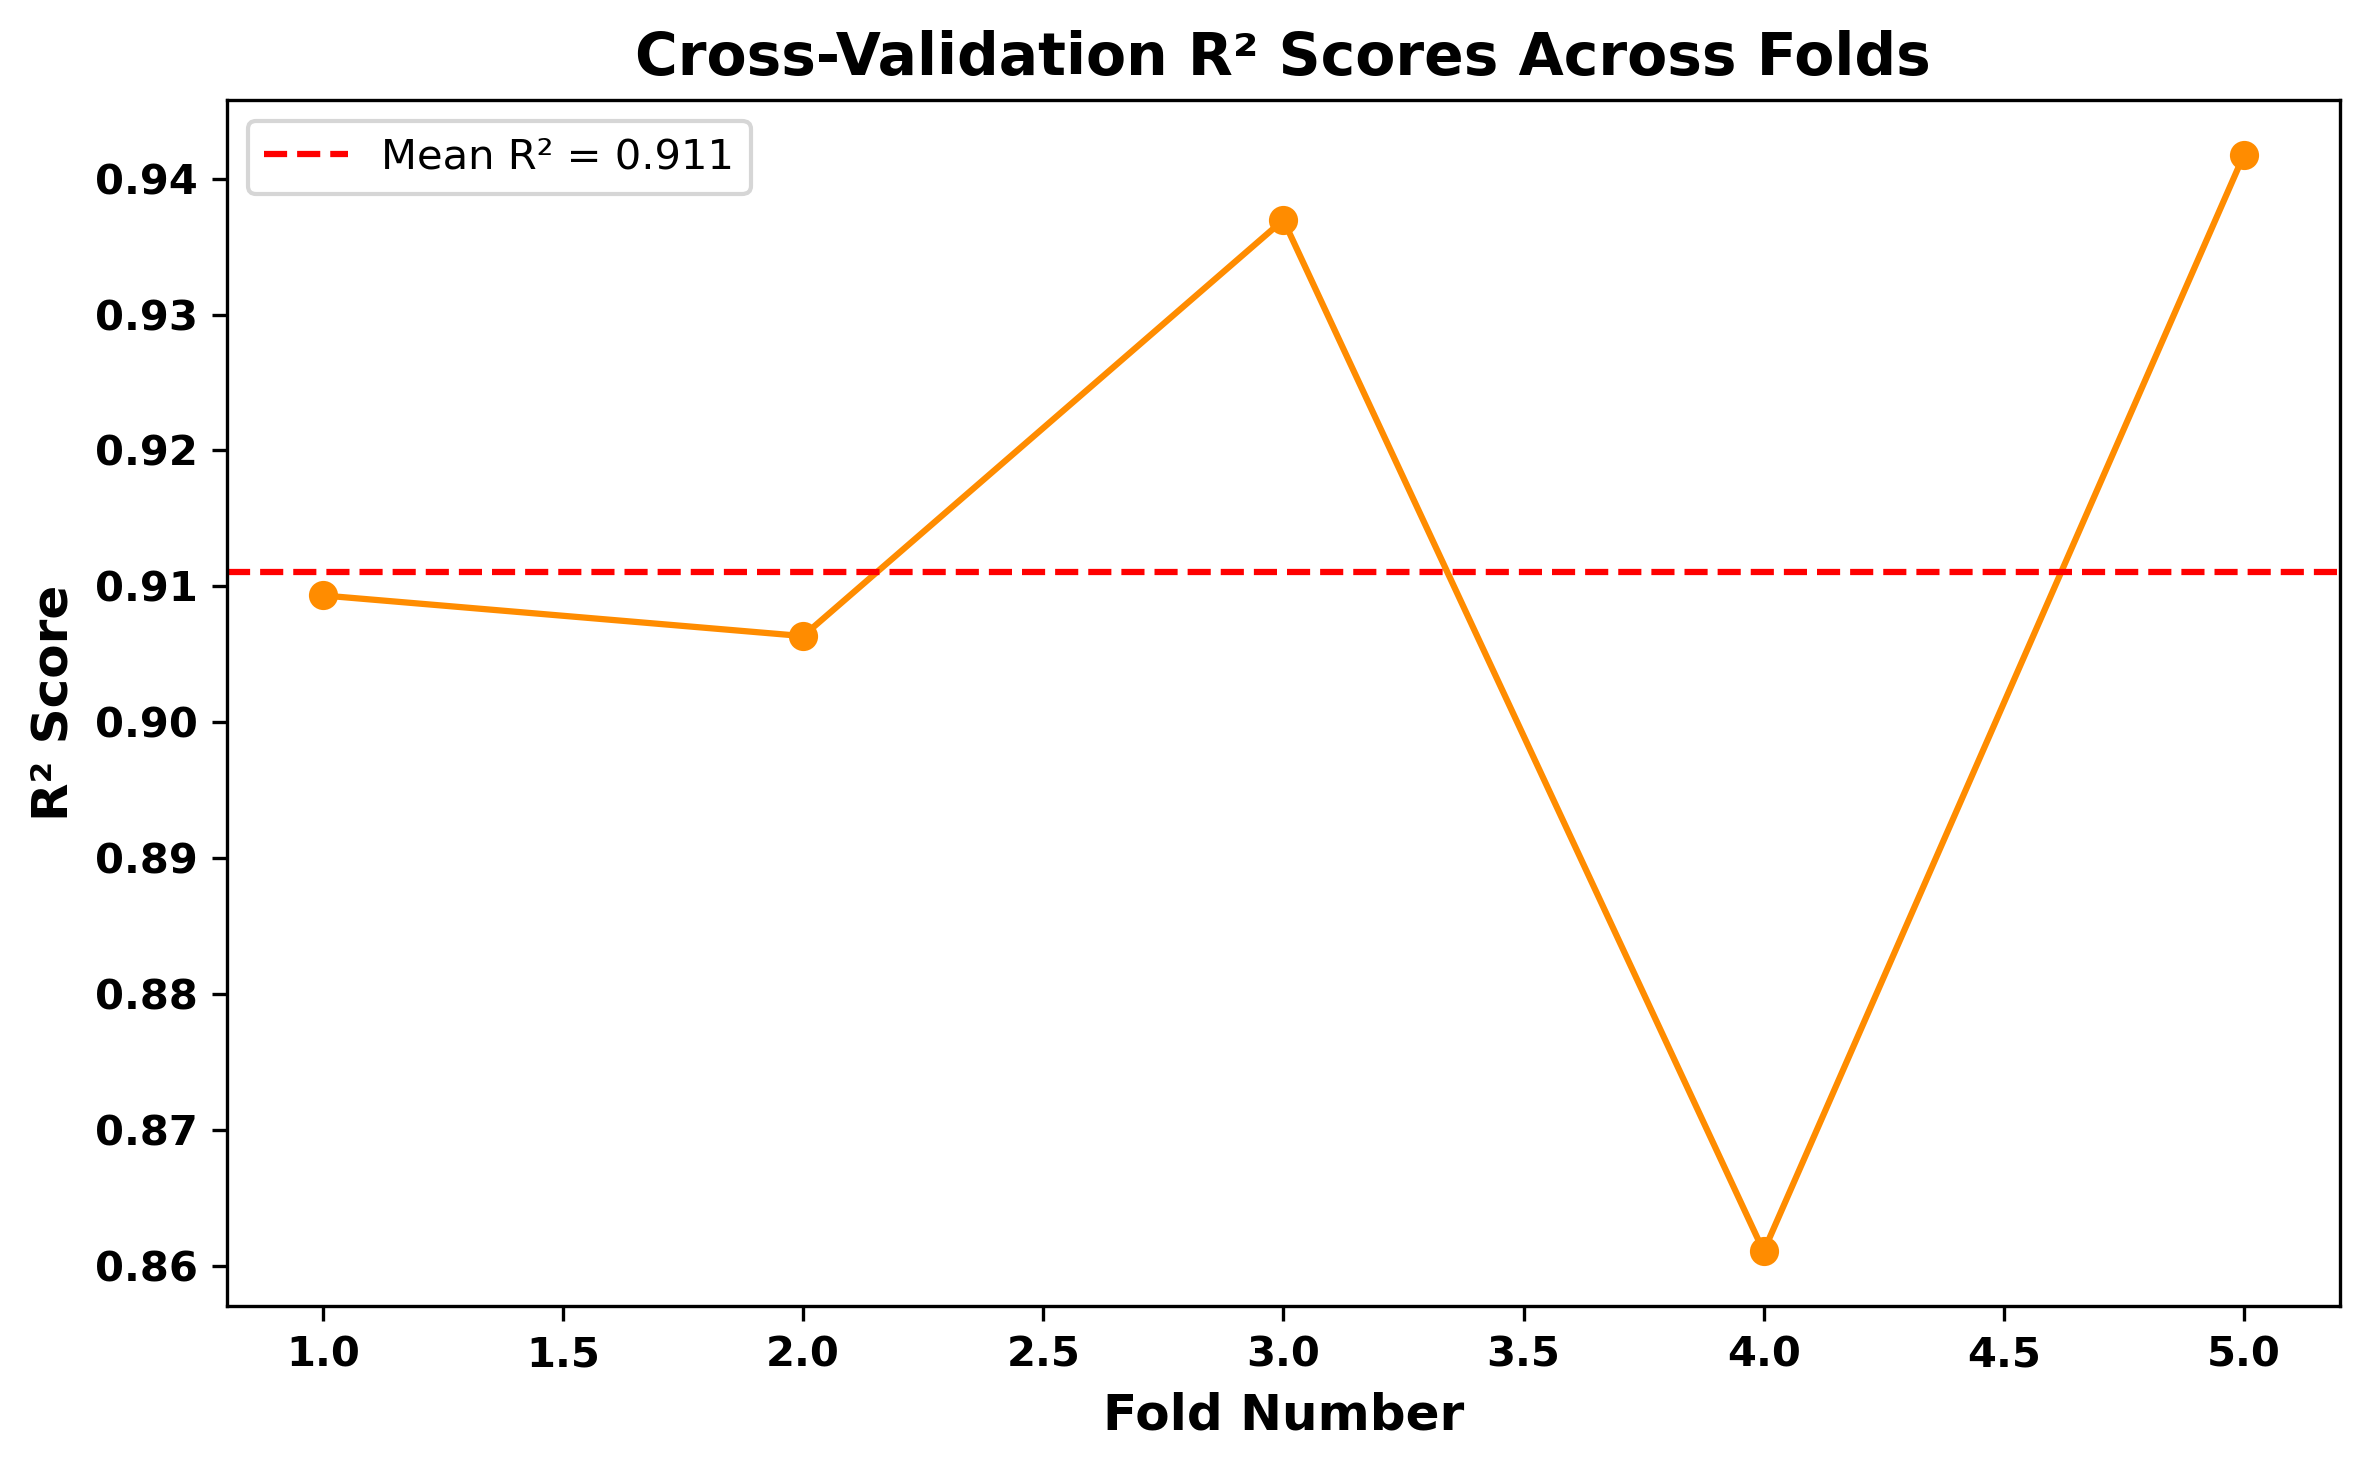

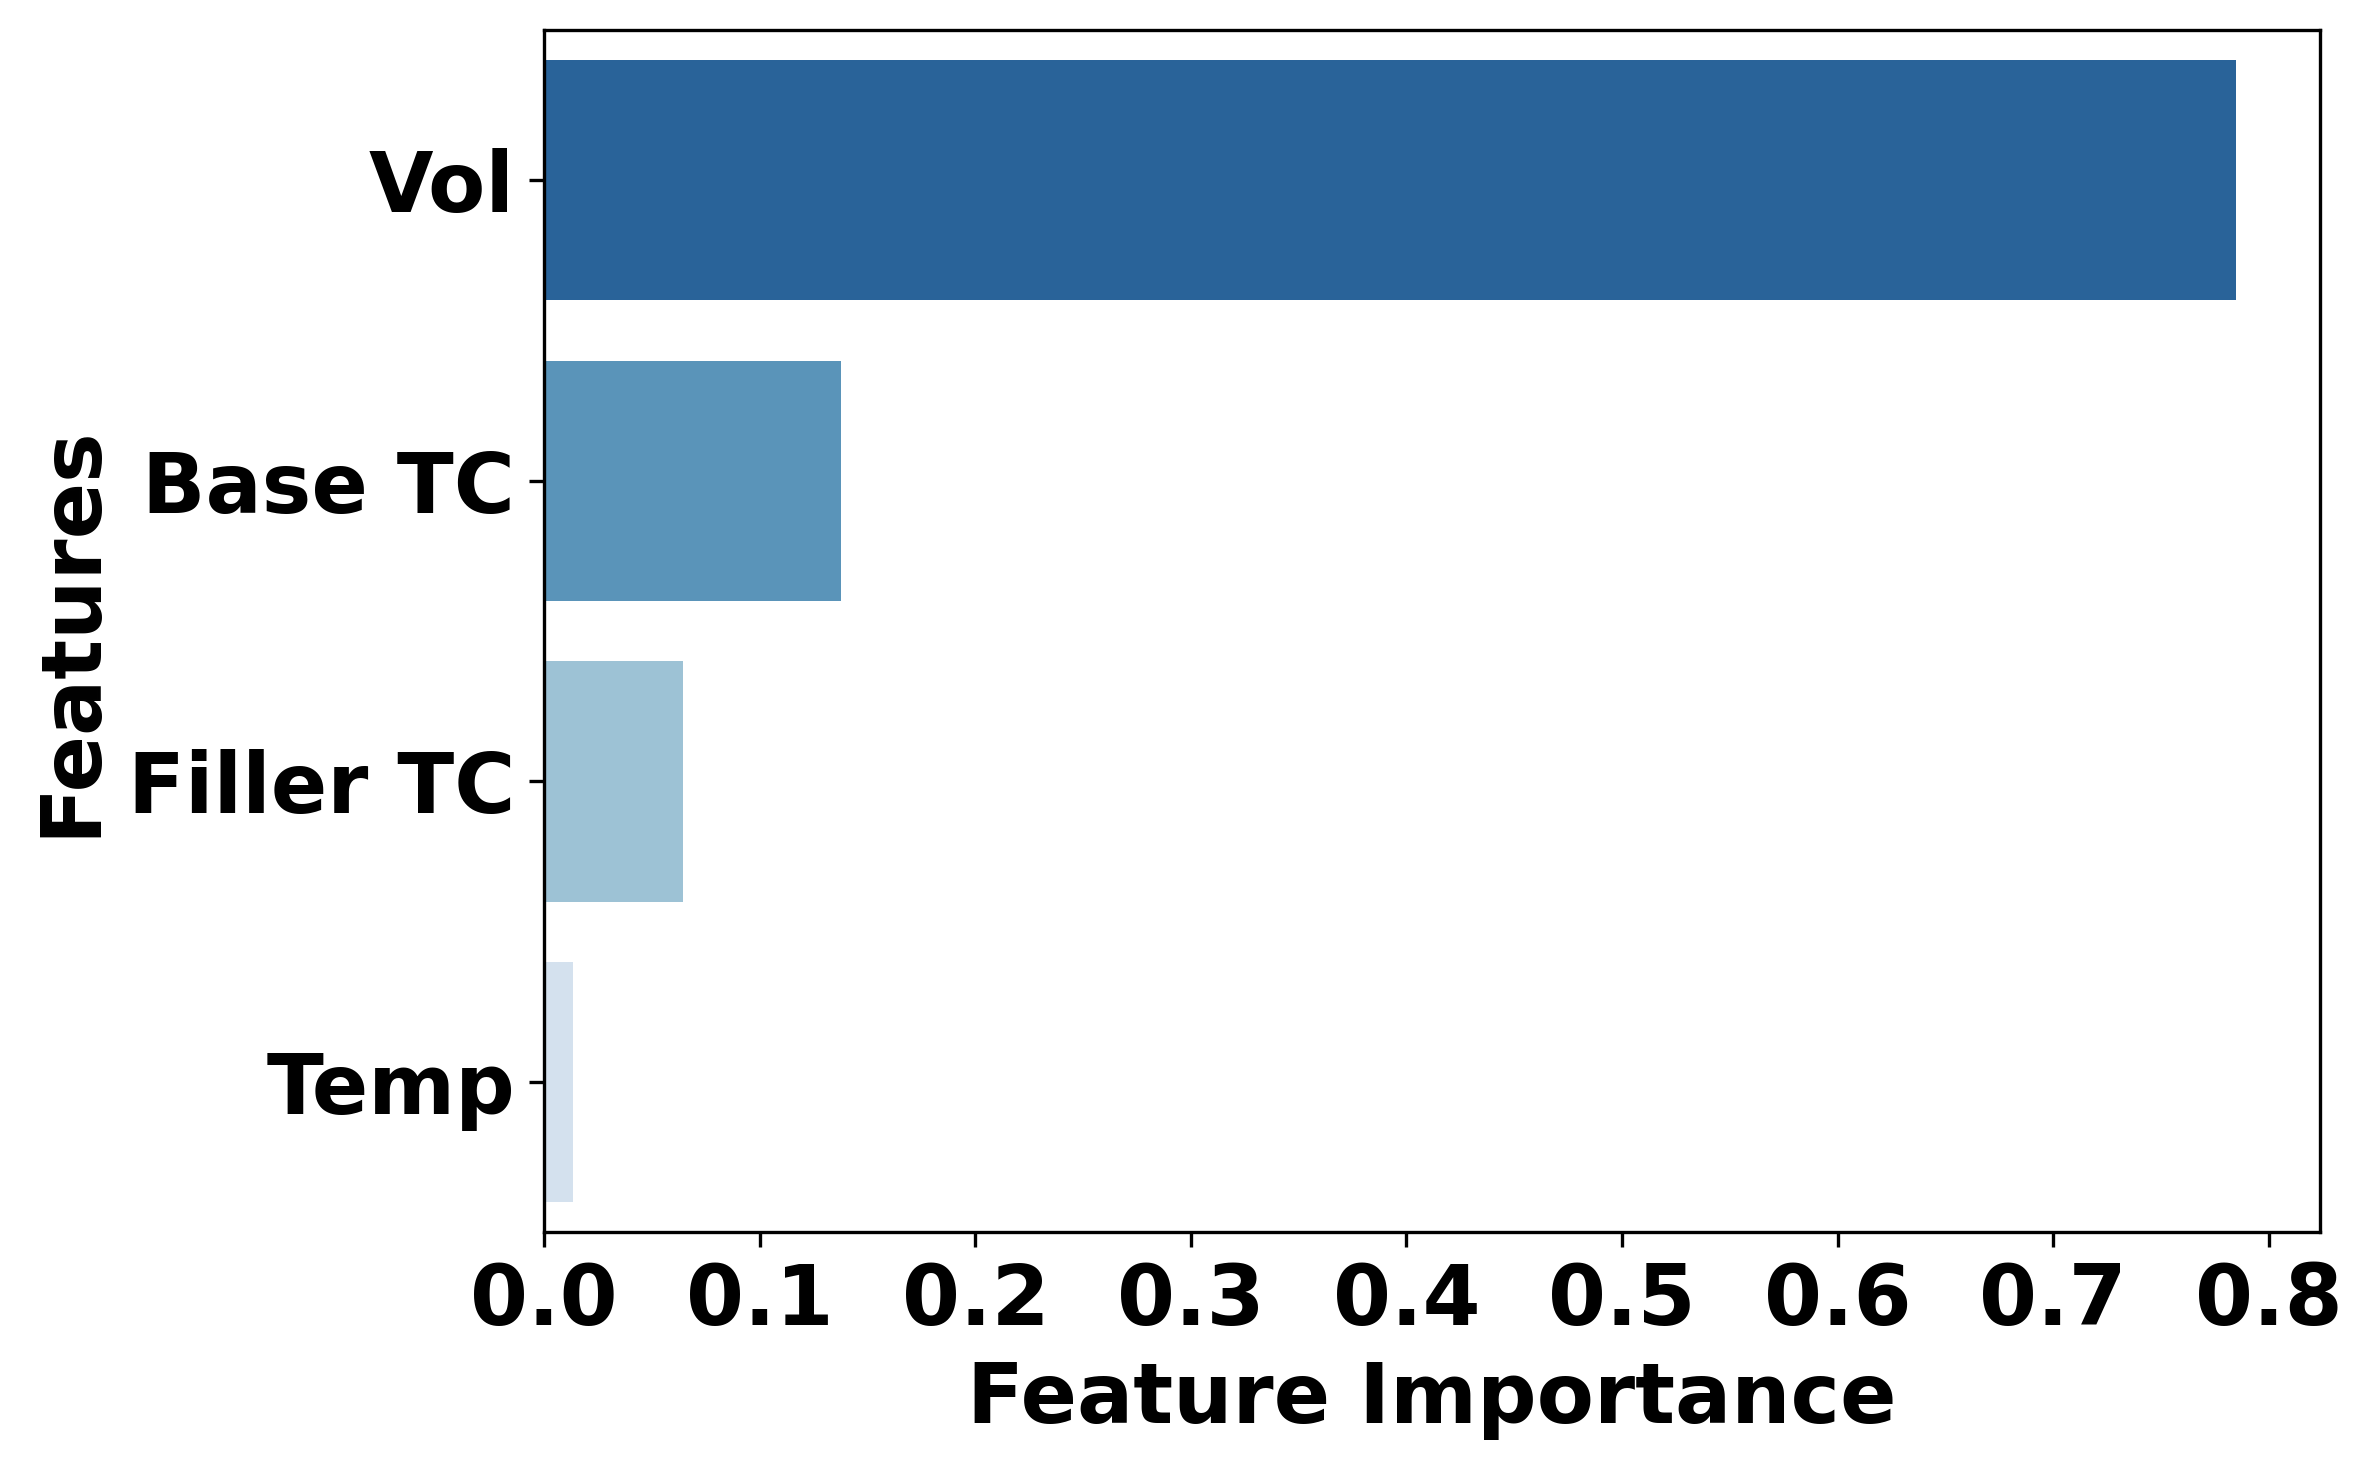

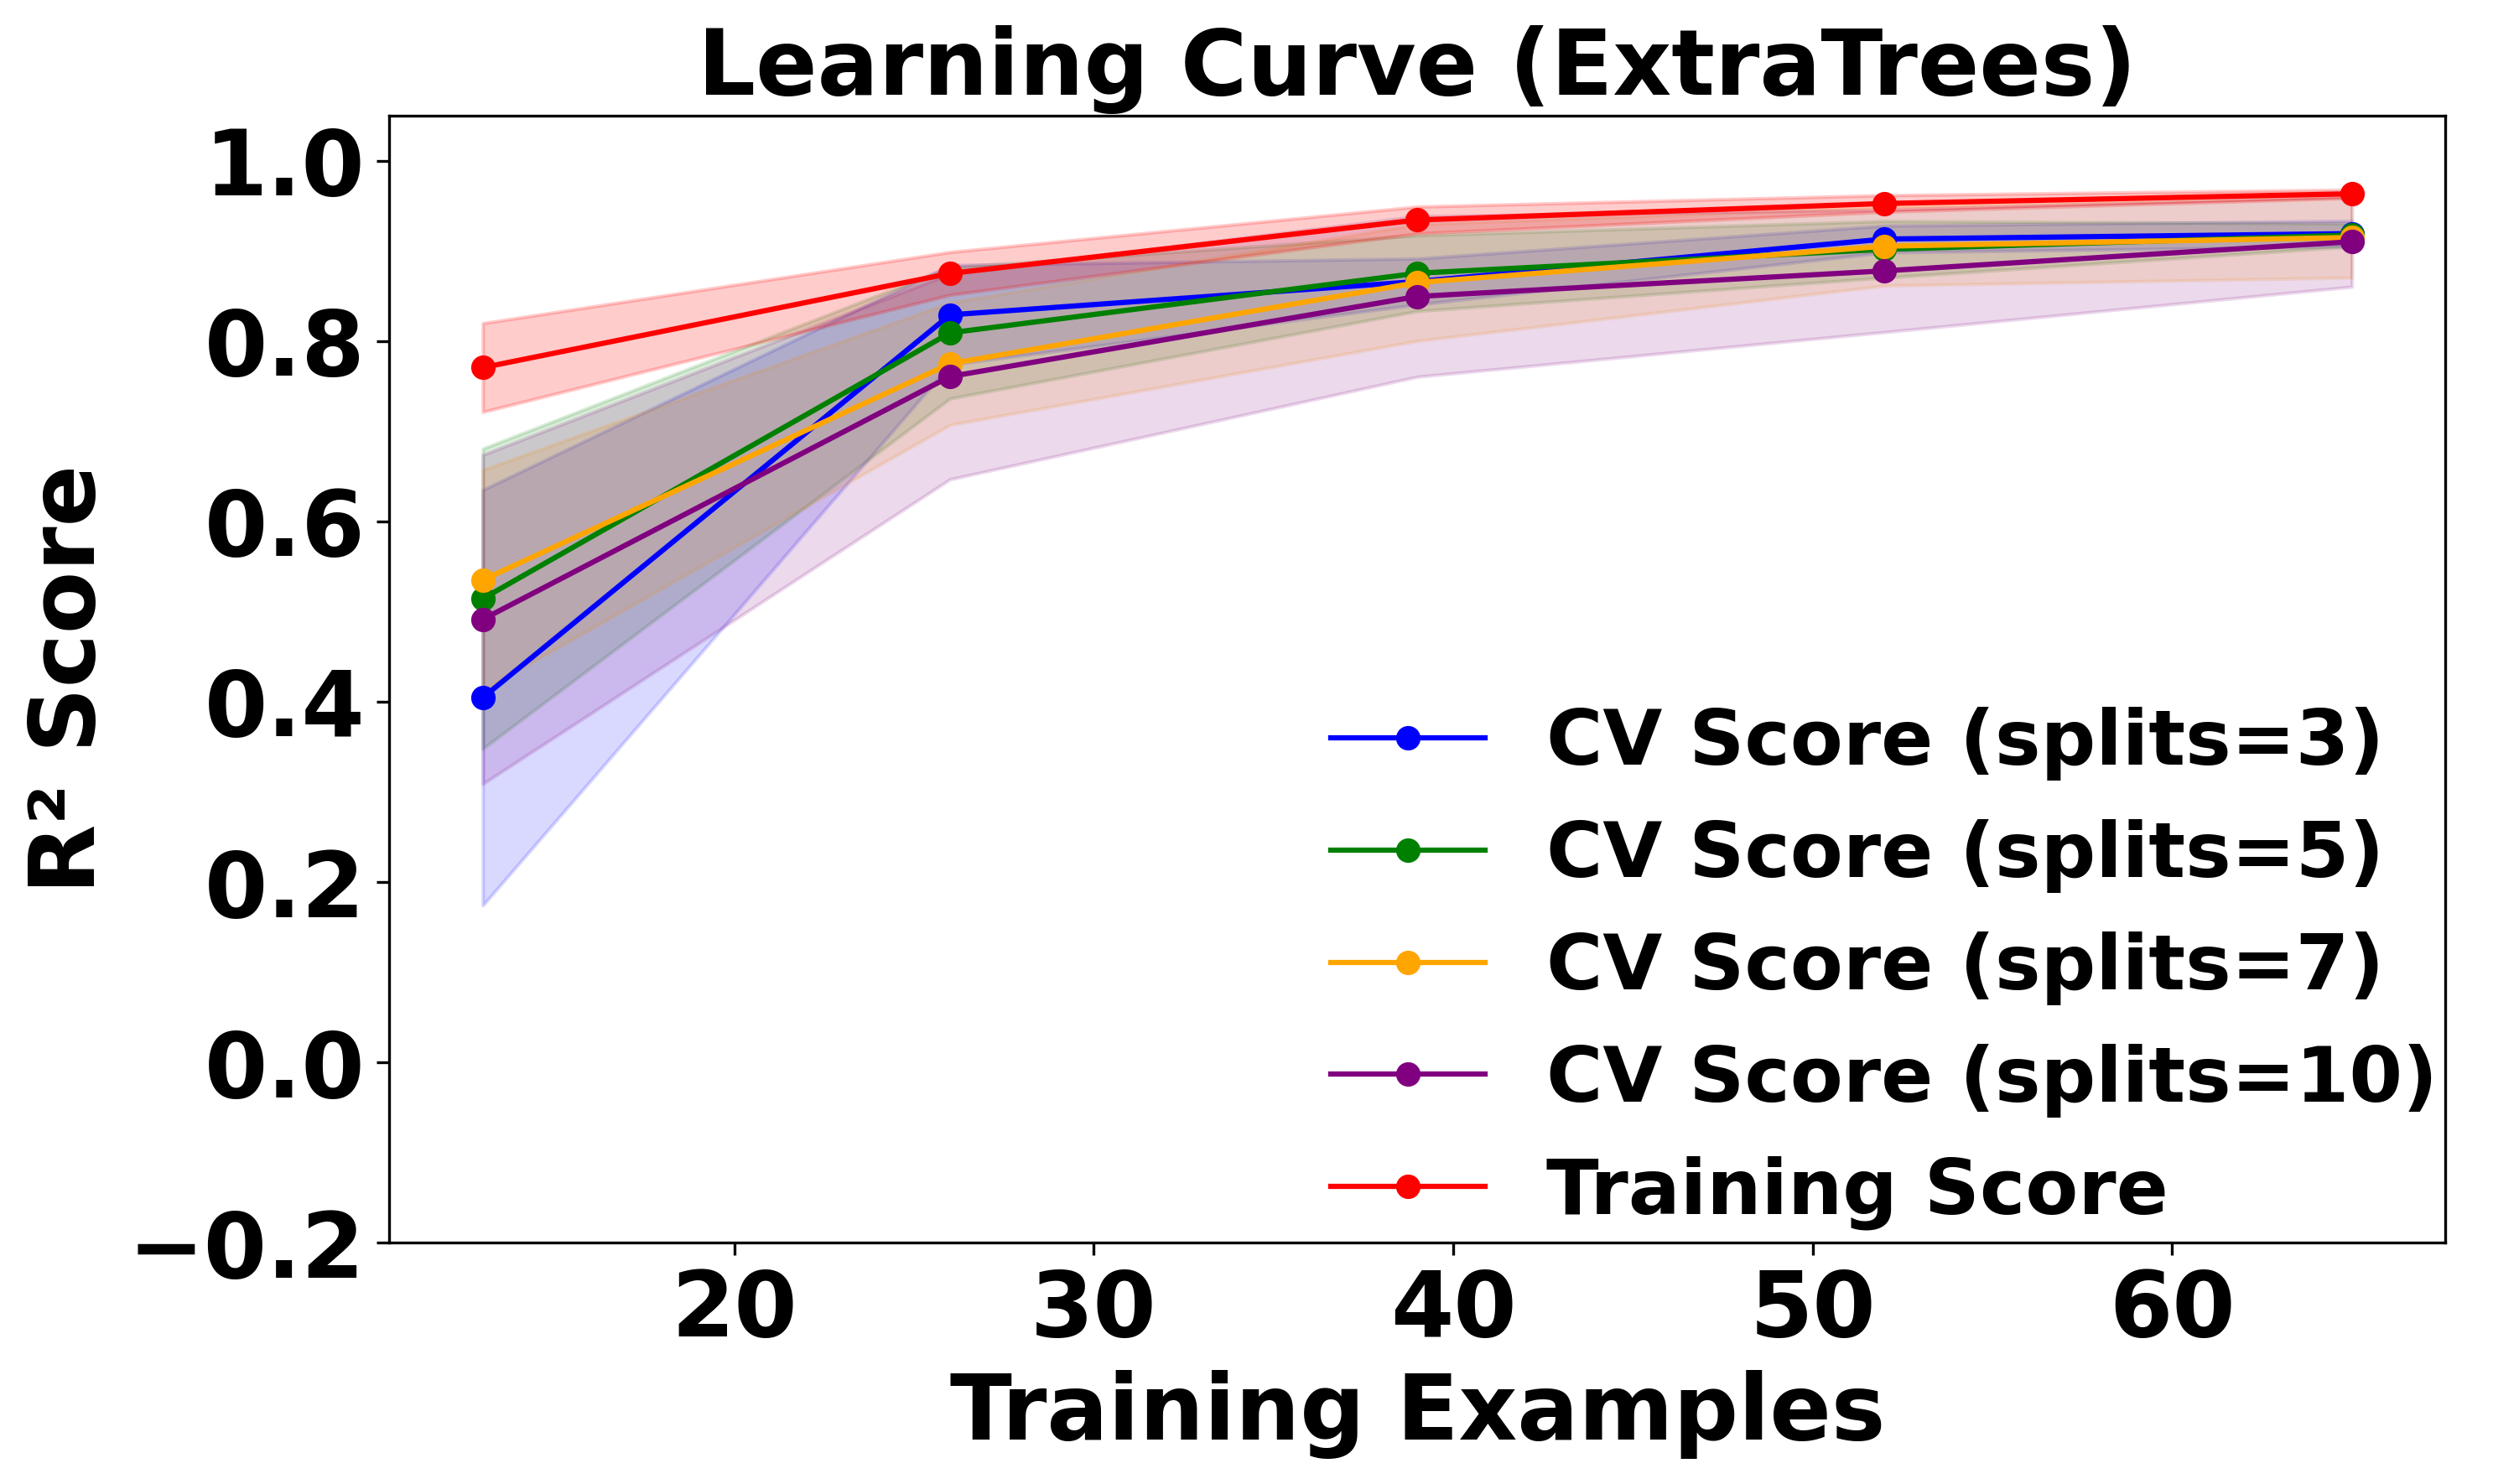


 Predicted Composite TC for input [1.07, 28, 5, 323]: 0.9841


C:\Users\manas\anaconda3\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(


In [5]:
#Imports
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold, learning_curve
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.utils import shuffle

# Load Dataset
file_path = r'C:\Users\manas\OneDrive\Desktop\Ml edit 22\High\High_Temp_3x_Augmented_1Percent_Noise.xlsx'
df = pd.read_excel(file_path)

# Features and Target
X = df[['Base TC', 'Filler TC', 'Vol', 'Temp']]
y = df['Composite TC']

# Shuffle before split (for balanced CV)
X, y = shuffle(X, y, random_state=42)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Tuned ExtraTreesRegressor with best hyperparameters
model = ExtraTreesRegressor(
    n_estimators=150,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.8,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

#Train Model
start = time.time()
model.fit(X_train, y_train)
end = time.time()
print(f"\n⏱ Training Time: {end - start:.2f} seconds")

# 📈 Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

#Evaluation Function
def print_scores(y_true, y_pred, label=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{label} Scores:")
    print(f"  MAE:  {mae:.5f}")
    print(f"  RMSE: {rmse:.5f}")
    print(f"  R²:   {r2:.5f}")

# 🧾 Final Evaluation
print_scores(y_train, y_train_pred, "Train Scores")
print_scores(y_test, y_test_pred, "Test Scores")

#5-Fold Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1)
print("\n📉 5-Fold Cross-Validation R² Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: R² = {score:.5f}")
print(f"\nMean R²: {cv_scores.mean():.5f}")
print(f"Std Dev: {cv_scores.std():.5f}")

#Scatter Plot with ±10% Band
y_true = y_test.values
y_pred = y_test_pred
lower = y_true * 0.80
upper = y_true * 1.20
sorted_idx = np.argsort(y_true)

plt.figure(figsize=(8, 6), dpi=300)
plt.scatter(y_true, y_pred, color='royalblue', s=60, edgecolor='black')
plt.fill_between(np.sort(y_true), lower[sorted_idx], upper[sorted_idx], color='gray', alpha=0.2)
plt.plot([0, 2.0], [0, 2.0], 'k--', lw=1)
plt.xlim(0.5, 2.10)
plt.ylim(0.5, 2.10)
plt.xlabel('Actual TC (W/mK)', fontsize=26, fontweight='bold')
plt.ylabel('Predicted TC (W/mK)', fontsize=26, fontweight='bold')
plt.title('ExtraTrees', fontsize=26, fontweight='bold')
plt.locator_params(axis='x', nbins=6)
plt.locator_params(axis='y', nbins=6)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

#  Line Plot of CV Scores
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(range(1, len(cv_scores)+1), cv_scores, marker='o', linestyle='-', color='darkorange')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean R² = {cv_scores.mean():.3f}')
plt.title('Cross-Validation R² Scores Across Folds', fontsize=14, fontweight='bold')
plt.xlabel('Fold Number', fontsize=12, fontweight='bold')
plt.ylabel('R² Score', fontsize=12, fontweight='bold')
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.grid(False)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

#Feature Importance
importances = model.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 5), dpi=300)
sns.barplot(x=importances[indices], y=feature_names[indices], palette="Blues_r")
plt.xlabel('Feature Importance', fontsize=20, fontweight='bold')
plt.ylabel('Features', fontsize=20, fontweight='bold')
# Set x-tick step size to 0.10
max_val = importances[indices].max()
plt.xticks(np.arange(0, max_val + 0.10, 0.10), fontsize=20, fontweight='bold')
plt.xticks(fontsize=20, fontweight='bold')
plt.yticks(fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()

#  Learning Curve
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
# train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)
step = min_allowed_size // 5
train_sizes_fixed = np.arange(step, min_allowed_size + 1, step)

plt.figure(figsize=(10, 6), dpi=300)
for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='r2',
        n_jobs=-1
    )
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    plt.plot(train_sizes, val_mean, marker='o', color=color, label=f'CV Score (splits={split})')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color=color, alpha=0.15)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
plt.plot(train_sizes, train_mean, marker='o', color='red', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='red', alpha=0.2)

plt.title('Learning Curve (ExtraTrees)', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('R² Score', fontsize=26, fontweight='bold')
plt.legend(loc='lower right', bbox_to_anchor=(1.03, -0.05), prop={'weight': 'bold', 'size': 22}, frameon=False)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.ylim(-0.2, 1.05)
plt.grid(False)
plt.tight_layout()
plt.show()

#  Manual Prediction
manual_input = [[1.07, 28, 5, 323]]  # Format: [Base TC, Filler TC, Vol, Temp]
predicted_tc = model.predict(manual_input)
print(f"\n Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")

In [6]:
# # Unpack the manual input values
# base_tc, filler_tc, vol, temp = manual_input[0]

# # Set a tolerance margin (±5%) for approximate match
# tolerance = 0.05

# # Filter the dataset for similar entries
# similar_rows = df[
#     (df['Base TC'].between(base_tc * (1 - tolerance), base_tc * (1 + tolerance))) &
#     (df['Filler TC'].between(filler_tc * (1 - tolerance), filler_tc * (1 + tolerance))) &
#     (df['Vol'].between(vol * (1 - tolerance), vol * (1 + tolerance))) &
#     (df['Temp'].between(temp * (1 - tolerance), temp * (1 + tolerance)))
# ]

# # Display matching entries
# if not similar_rows.empty:
#     print(f"\n🔍 Found {len(similar_rows)} similar row(s) in the dataset:")
#     print(similar_rows.head())
# else:
#     print("\n No close matches found for the manual input in the dataset.")

# # 🔍 Manual Prediction
# manual_input = [[1.07, 28, 5, 323]]  # Format: [Base TC, Filler TC, Vol, Temp]
# predicted_tc = model.predict(manual_input)
# print(f"\n🧪 Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")



In [7]:
# # 🔮 Manual Prediction with Bound Check
# manual_input = [[0.5, 28, 5, 323]]  # Format: [Base TC, Filler TC, Vol, Temp]
# input_labels = ['Base TC', 'Filler TC', 'Vol', 'Temp']

# # Convert to DataFrame for easy comparison
# input_df = pd.DataFrame(manual_input, columns=input_labels)

# # Check each feature against min/max in dataset
# print("\n🔍 Manual Input Bound Check:")
# for col in input_labels:
#     min_val = df[col].min()
#     max_val = df[col].max()
#     input_val = input_df.at[0, col]
#     if input_val < min_val or input_val > max_val:
#         print(f"⚠️ {col} = {input_val} is outside the data range [{min_val:.2f}, {max_val:.2f}]")
#     else:
#         print(f"✅ {col} = {input_val} is within the data range [{min_val:.2f}, {max_val:.2f}]")

# # Perform prediction
# predicted_tc = model.predict(manual_input)
# print(f"\n🧪 Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")


In [8]:
#  Manual Prediction
manual_input = [[1.07, 28, 14, 323]]  # Format: [Base TC, Filler TC, Vol, Temp]
predicted_tc = model.predict(manual_input)
print(f"\n Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")


 Predicted Composite TC for input [1.07, 28, 14, 323]: 1.3069


C:\Users\manas\anaconda3\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(


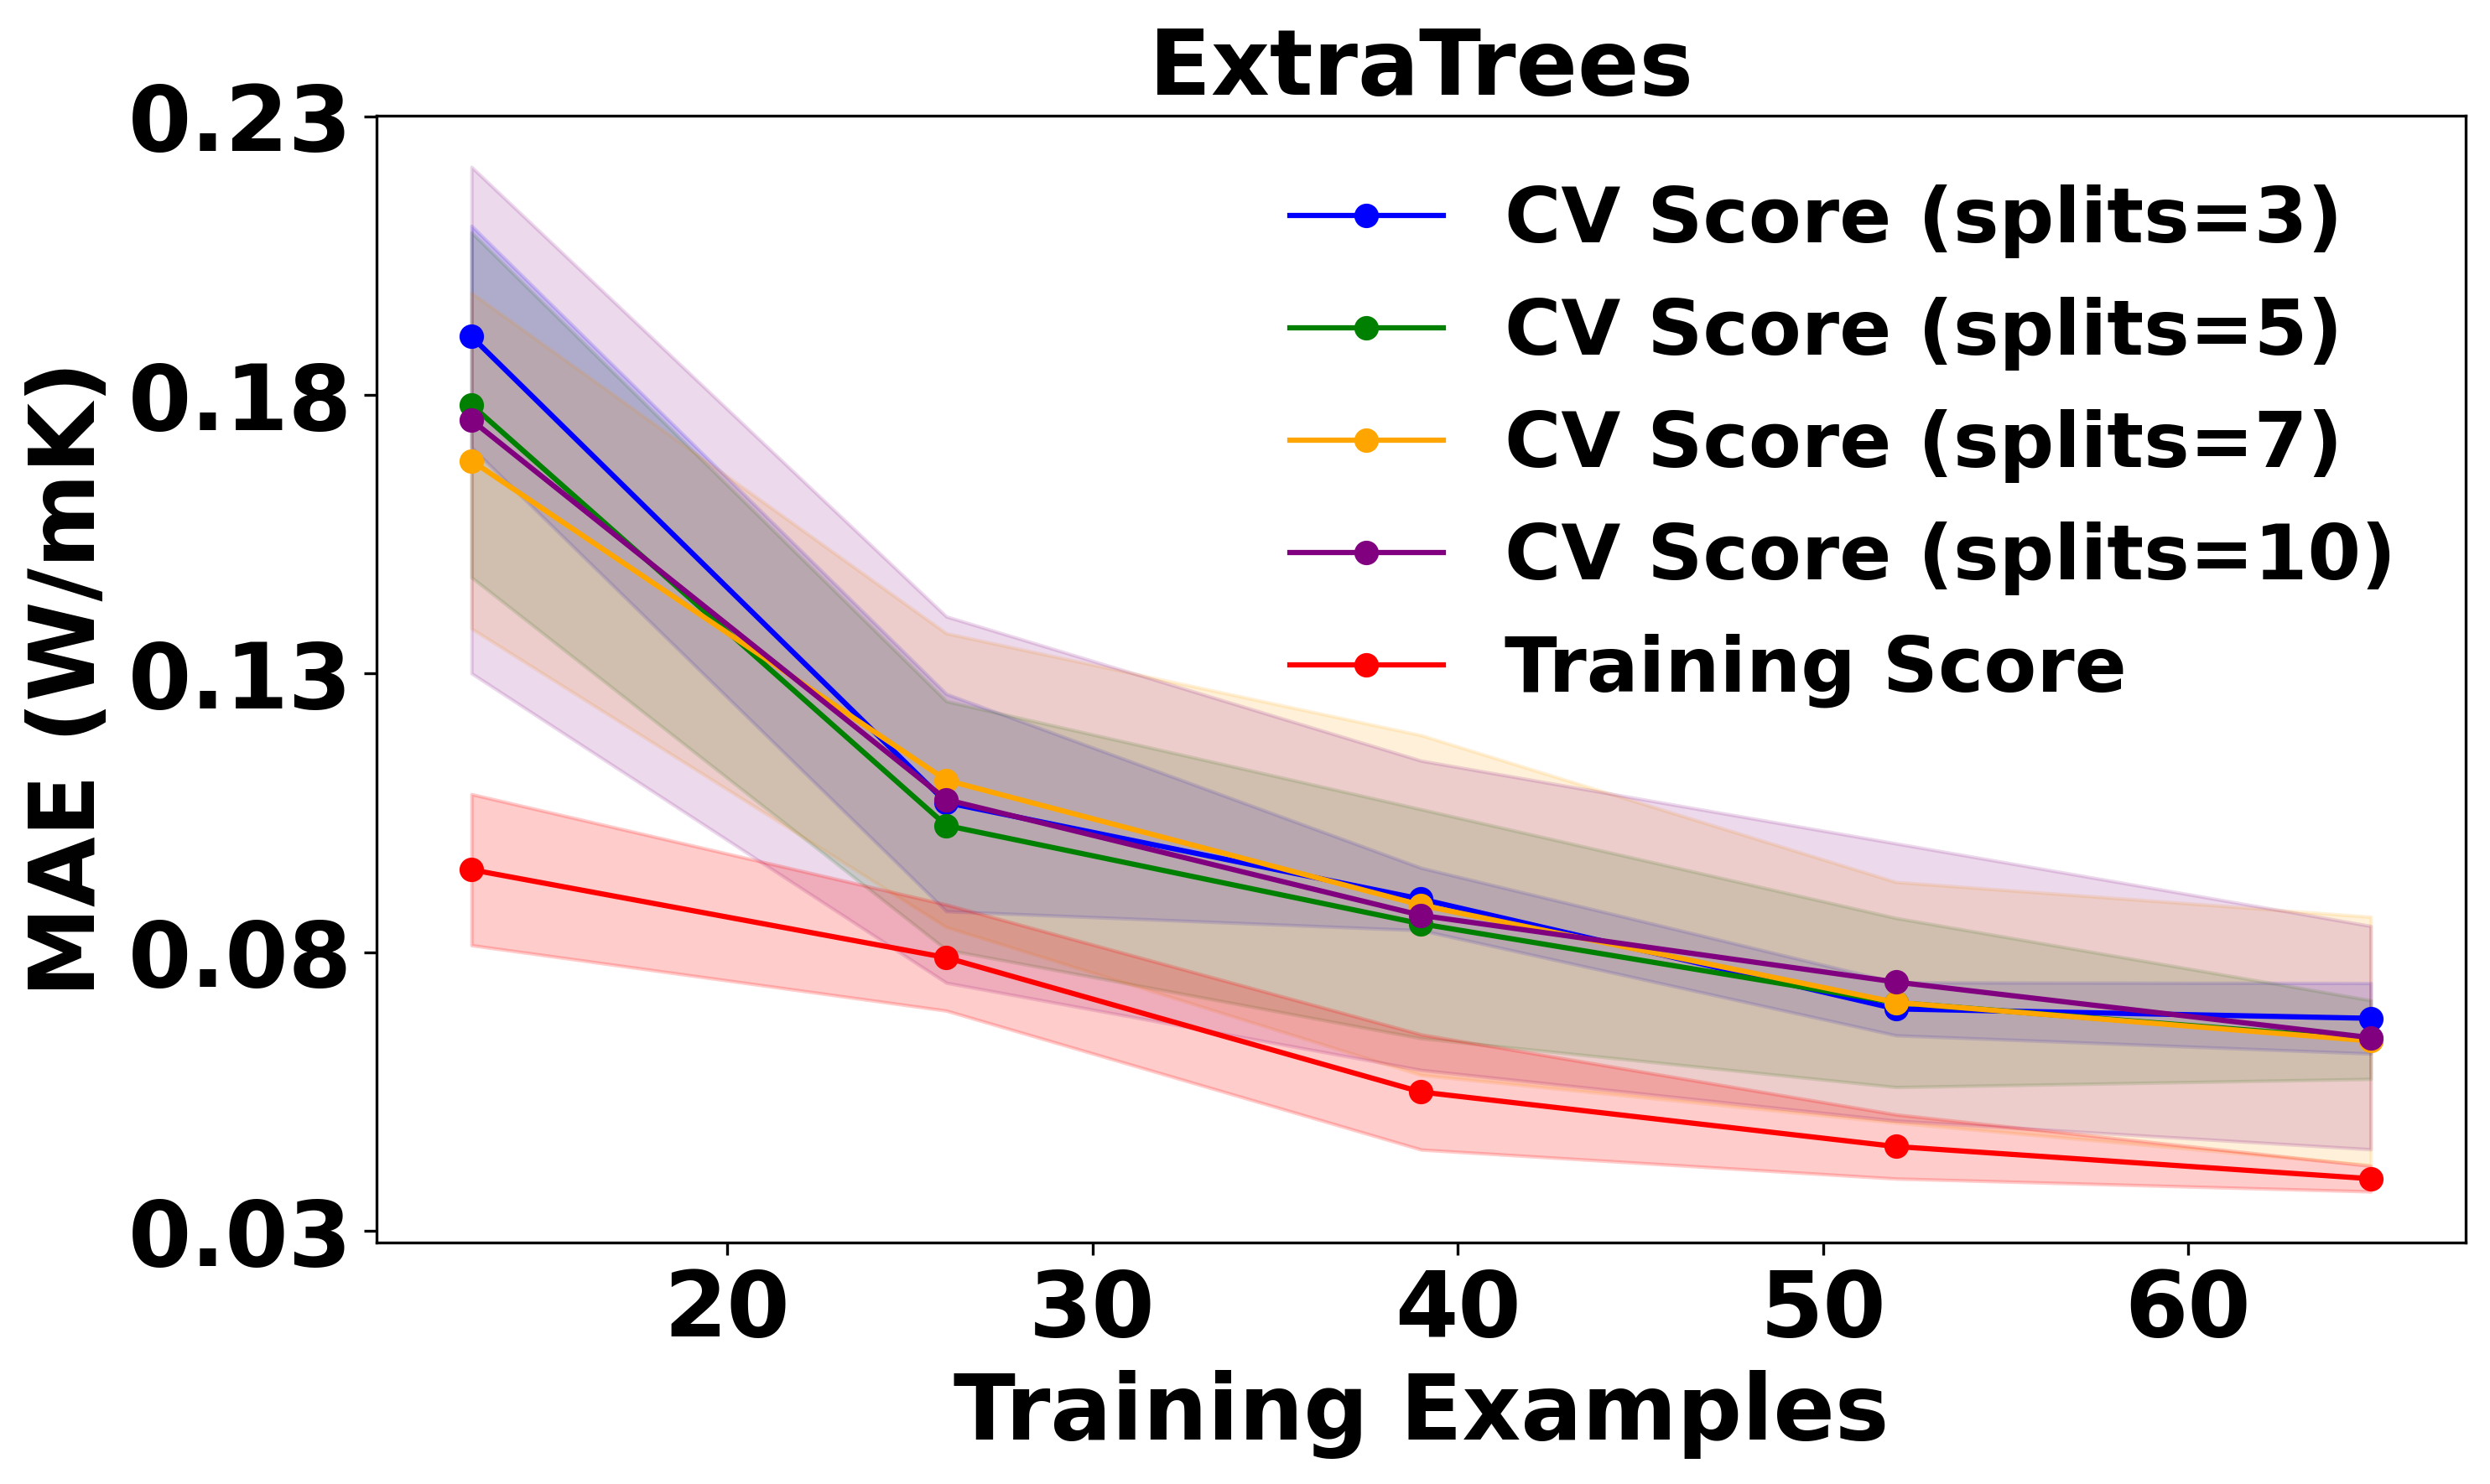

In [13]:
# Learning Curve (MAE)
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
# train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)
step = min_allowed_size // 5
train_sizes_fixed = np.arange(step, min_allowed_size + 1, step)


plt.figure(figsize=(10, 6), dpi=300)

for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    val_mean = -np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    plt.plot(train_sizes, val_mean, marker='o',
             label=f'CV Score (splits={split})',
             color=color)

    plt.fill_between(train_sizes,
                     val_mean - val_std,
                     val_mean + val_std,
                     color=color,
                     alpha=0.15)

train_mean = -np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)

plt.plot(train_sizes, train_mean, marker='o',
         color='red', label='Training Score')

plt.fill_between(train_sizes,
                 train_mean - train_std,
                 train_mean + train_std,
                 color='red', alpha=0.2)

plt.title('ExtraTrees', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('MAE (W/mK)', fontsize=26, fontweight='bold')

# 🔹 Set Y-axis step to 0.05
y_min, y_max = plt.ylim()
plt.yticks(np.arange(round(y_min, 2), round(y_max, 2) + 0.05, 0.05),
           fontsize=26, fontweight='bold')

plt.xticks(fontsize=26, fontweight='bold')

# 🔹 Legend at top right
plt.legend(loc='upper right',
           prop={'weight': 'bold', 'size': 22},
           frameon=False)

plt.grid(False)
plt.tight_layout()
plt.show()
